In [1]:
from datetime import date

today = date.today()
print(f'Last full compilation {today}')

Last full compilation 2023-05-30


# Cas de référence : échantillon monolithique

Noms des campagnes : 
- `campagne_honey`
- `campagne_honey_CC`
- `campagne_honey_UR3_S13`
- `campagne_honey_UR3_S7`

## Mapping sans CC en fct de theta et la taille du motif

In [2]:
from classes import *
from funcData import *
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
from math import *
import os 

import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 100


campagnes = ['campagne_honey','campagne_carre','campagne_trian', 'campagne_hexac']
# Can be long the first time
data=read_data_from_campaigns(campagnes)
data_bulk = get_bulk_data(data)

Lecture des données réalisée en 2.32057s


[18.17, 94.22, 157.66, 145.24]


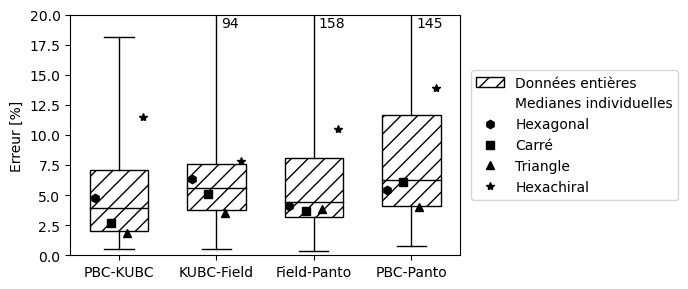

In [3]:
err = [[] for i in range(4)]

for _, test in data_bulk.items():
    err[0].append(test.get_err((0, 1)))
    err[1].append(test.get_err((1, 2)))
    err[2].append(test.get_err((2, 3)))
    err[3].append(test.get_err((0, 3)))
print([max(i) for i in err])

mean_err_per_geo = np.zeros((4, 4, max([len(c) for _, c in data.items()])))
mean_err_per_geo[:] = np.nan
counter = [0, 0, 0, 0]

for c_name, campagne in data.items():
    geo_idx = campagnes.index(c_name)
    for _, test in campagne.items():
        mean_err_per_geo[0, geo_idx, counter[geo_idx]] = test.get_err((0, 1))
        mean_err_per_geo[1, geo_idx, counter[geo_idx]] = test.get_err((1, 2))
        mean_err_per_geo[2, geo_idx, counter[geo_idx]] = test.get_err((2, 3))
        mean_err_per_geo[3, geo_idx, counter[geo_idx]] = test.get_err((0, 3))
        counter[geo_idx] += 1

mean_err_per_geo = np.nanquantile(mean_err_per_geo,0.5, axis=2).tolist()

plt.figure(figsize=(7, 3))
bp=plt.boxplot(err, patch_artist=True, whis=(0, 100), medianprops={
            'color': 'k'}, boxprops={'fill': False, 'hatch':'//'},widths=0.6)

# * Legende
nn = mlines.Line2D([], [], color='w', marker='*', linestyle='')
hexa = mlines.Line2D([], [], color='k', marker='h', linestyle='')
carre = mlines.Line2D([], [], color='k', marker='s', linestyle='')
trian = mlines.Line2D([], [], color='k', marker='^', linestyle='')
hc = mlines.Line2D([], [], color='k', marker='*', linestyle='')
plt.legend([bp['boxes'][0],nn, hexa,carre,trian,hc],['Données entières','Medianes individuelles','Hexagonal','Carré', 'Triangle', 'Hexachiral'],
           fancybox=True,loc='center left', bbox_to_anchor=(1.01, 0.5))


plt.ylim(top=20, bottom=0)
plt.ylabel('Erreur [%]')
plt.xticks(range(1, 5), ['PBC-KUBC',
                         'KUBC-Field',
                         'Field-Panto',
                         'PBC-Panto'])

plt.text(2.05,19.9,'94', va='top', ha='left')
plt.text(3.05,19.9,'158', va='top', ha='left')
plt.text(4.05,19.9,'145', va='top', ha='left')


markers = ['h', 's', '^', '*']
n=6 # Space between indivuals medians
for i_error, error in enumerate(mean_err_per_geo):
    for i_geo, geo in enumerate(error):
        plt.plot([i_error+1-(1/n+1/n/2)+1/n*i_geo], [geo], 'k'+markers[i_geo])


plt.tight_layout()
plt.savefig('images/mapping_error_glob.pdf')


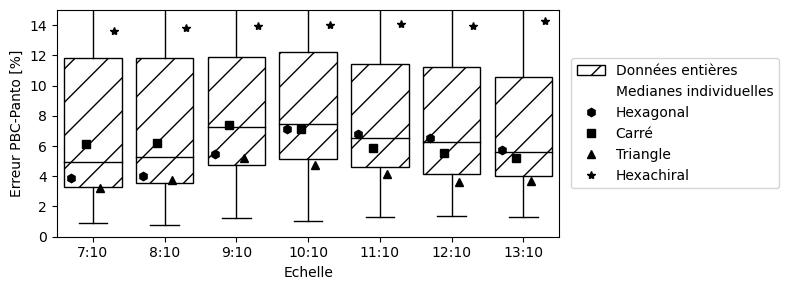

In [4]:

err = [[] for i in range(7)]

for test_id, test in data_bulk.items():
    err[int(test_id.split('_')[1])-7].append(test.get_err((0, 3)))

mean_err_per_geo = np.zeros((7, 4, max([len(c) for _, c in data.items()])))
mean_err_per_geo[:] = np.nan
counter = np.zeros((7,4))

for c_name, campagne in data.items():
    geo_idx = campagnes.index(c_name)
    for test_id, test in campagne.items():
        scale=int(test_id.split('_')[1])-7
        mean_err_per_geo[scale, geo_idx, int(counter[scale,geo_idx])] = test.get_err((0, 3))
        counter[scale,geo_idx] += 1

mean_err_per_geo = np.nanquantile(mean_err_per_geo,0.5, axis=2).tolist()

plt.figure(figsize=(8, 3))
bp=plt.boxplot(err, patch_artist=True, whis=(0, 100), medianprops={
            'color': 'k'}, boxprops={'fill': False, 'hatch':'/'},widths=0.8)

# * Legende
nn = mlines.Line2D([], [], color='w', marker='*', linestyle='')
hexa = mlines.Line2D([], [], color='k', marker='h', linestyle='')
carre = mlines.Line2D([], [], color='k', marker='s', linestyle='')
trian = mlines.Line2D([], [], color='k', marker='^', linestyle='')
hc = mlines.Line2D([], [], color='k', marker='*', linestyle='')
plt.legend([bp['boxes'][0],nn, hexa,carre,trian,hc],['Données entières','Medianes individuelles','Hexagonal','Carré', 'Triangle', 'Hexachiral'],
           fancybox=True,loc='center left', bbox_to_anchor=(1.01, 0.5))




markers = ['h', 's', '^', '*']
n=5 # Space between indivuals medians
for i_error, error in enumerate(mean_err_per_geo):
    for i_geo, geo in enumerate(error):
        plt.plot([i_error+1-(1/n+1/n/2)+1/n*i_geo], [geo], 'k'+markers[i_geo])

# ax=plt.gca()
# ax.set_yscale('log')
# ax.set_yticks([1, 2,5,10,100])
# ax.get_yaxis().set_major_formatter(mpl.ticker.ScalarFormatter())
plt.ylim(bottom=0.0,top=15)

plt.xlabel('Echelle')
plt.ylabel('Erreur PBC-Panto [%]')
plt.xticks(range(1, 8), ['7:10','8:10','9:10','10:10','11:10','12:10','13:10'])

plt.tight_layout()
plt.savefig('images/error_per_scale.pdf')

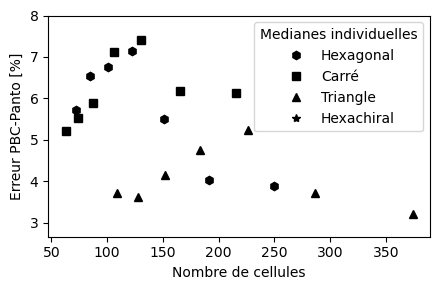

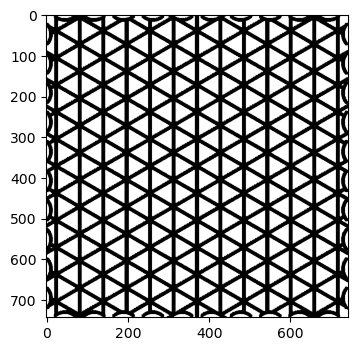

7.61


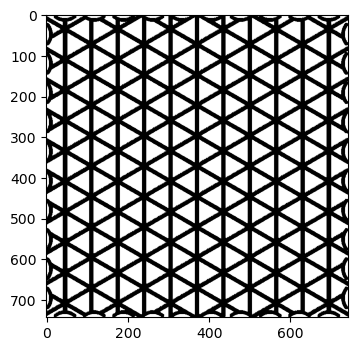

6.98


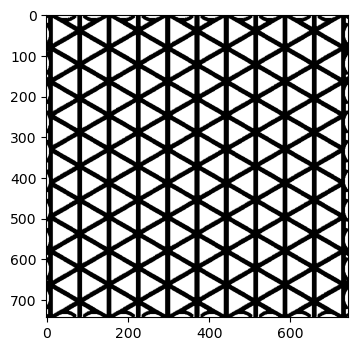

13.37


In [5]:
nb_cell=[]

L0=28

for scale in range(7,14):
    L=L0*scale/10
    nb_cell.append([288**2/(L/2*L*tan(pi/6)+L*L*tan(pi/6)),         # Hexa
                         288**2/(L**2),                             # Carre
                         288**2/(L*L*tan(pi/6))])                   # Triangle



plt.figure(figsize=(4.5,3))
markers = ['h', 's', '^', '*']
n=5 # Space between indivuals medians
for i_error, error in enumerate(mean_err_per_geo):
    for i_geo, geo in enumerate(error):
        plt.plot(nb_cell[i_error][i_geo%3], [geo], 'k'+markers[i_geo])


# * Legende
nn = mlines.Line2D([], [], color='w', marker='*', linestyle='')
hexa = mlines.Line2D([], [], color='k', marker='h', linestyle='')
carre = mlines.Line2D([], [], color='k', marker='s', linestyle='')
trian = mlines.Line2D([], [], color='k', marker='^', linestyle='')
hc = mlines.Line2D([], [], color='k', marker='*', linestyle='')
plt.legend([hexa,carre,trian,hc],['Hexagonal','Carré', 'Triangle', 'Hexachiral'], title='Medianes individuelles',
           fancybox=True)


plt.xlabel('Nombre de cellules')
plt.ylabel('Erreur PBC-Panto [%]')
plt.ylim(top=8)

plt.tight_layout()
plt.savefig('images/error_per_nb_cells.pdf')
plt.show()
t_list=['tria_8_0_0_0', 'tria_9_0_0_0', 'tria_10_0_0_0']
for t in t_list:
    data_bulk[t].show_geo()
    print(data_bulk[t].get_err((0,3)))




Lecture des données réalisée en 0.16548s


Text(0, 0.5, '$\\Delta(\\mathrm{PBC},\\mathrm{Panto})-\\Delta(\\mathrm{PBC},\\mathrm{Panto})_{CC}$')

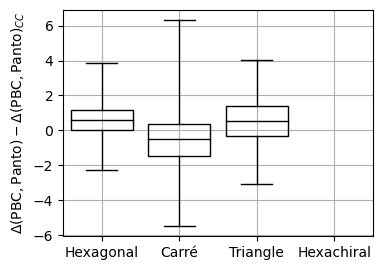

In [6]:

campagnes_CC = ['campagne_honey_CC','campagne_carre_CC','campagne_trian_CC', 'campagne_hexac_CC']
# Can be long the first time
data_CC=read_data_from_campaigns(campagnes_CC)
data_CC_bulk = get_bulk_data(data_CC)


amelioration=[[] for i in range(4)]
eoi=(0,3)

for c_name, campagne in data_CC.items():
    geo_idx = campagnes_CC.index(c_name)
    for test_id, test in campagne.items():
        try:
            ref=data_bulk[test_id.replace('CC','')]
        except:
            print(f'{test_id} non trouvé')
            continue
        amelioration[geo_idx].append(-(test.get_err(eoi)-ref.get_err(eoi)))


plt.figure(figsize=(4, 3))
bp=plt.boxplot(amelioration, patch_artist=True, whis=(0, 100), medianprops={
            'color': 'k'}, boxprops={'fill': False},widths=0.8)

plt.grid()

plt.xticks(range(1,5),['Hexagonal', 'Carré', 'Triangle', 'Hexachiral'])
plt.ylabel(r'$\Delta(\mathrm{PBC},\mathrm{Panto})-\Delta(\mathrm{PBC},\mathrm{Panto})_{CC}$')

Lecture des données réalisée en 0.59921s


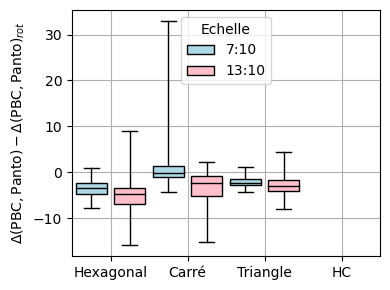

In [7]:

campagnes_R3 = ['campagne_honey_UR3_S7','campagne_honey_UR3_S13',
                'campagne_carre_UR3_S7','campagne_carre_UR3_S13',
                'campagne_trian_UR3_S7','campagne_trian_UR3_S13', 
                'campagne_hexac_UR3_S7','campagne_hexac_UR3_S13']
# Can be long the first time
data_R3=read_data_from_campaigns(campagnes_R3)



amelioration=[[] for i in range(8)]
eoi=(0,3)

for c_name, campagne in data_R3.items():
    geo_idx = campagnes_R3.index(c_name)
    for test_id, test in campagne.items():
        try:
            ref=data_bulk[test_id.replace('UR3','')]
        except:
            print(f'{test_id} non trouvé')
            continue
        amelioration[geo_idx].append(-(test.get_err(eoi)-ref.get_err(eoi)))


plt.figure(figsize=(4, 3))
bp=plt.boxplot(amelioration, patch_artist=True, whis=(0, 100), medianprops={
            'color': 'k'}, boxprops={'fill': True},widths=0.8)

i=0
for bplot in bp['boxes']:
    i+=1
    if i%2==0:
        bplot.set_facecolor('pink')
    else:
        bplot.set_facecolor('lightblue')


plt.legend([bp['boxes'][0],bp['boxes'][1]],['7:10','13:10'], title='Echelle',
           fancybox=True,loc='upper center',)
plt.grid()

plt.xticks([1.5,3.5,5.5,7.5],['Hexagonal', 'Carré', 'Triangle', 'HC'])
plt.ylabel(r'$\Delta(\mathrm{PBC},\mathrm{Panto})-\Delta(\mathrm{PBC},\mathrm{Panto})_{rot}$')

plt.tight_layout()
plt.savefig('images/UR3_effect.pdf')

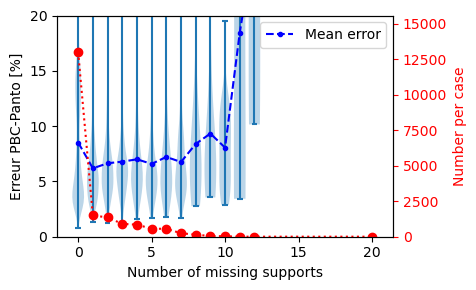

In [8]:

def err_per_number_of_ms(data: dict[Test], eoi:tuple=(0,3), step:float=0.9, width:float=0.1) -> None:
    x_scatter, y_scatter = [], []
    for _, test in data.items():
        err = test.global_err[eoi[0]][eoi[1]]
        number_missing_support = sum([len(i) for i in test.skipped_cyl])
        x_scatter.append(number_missing_support)
        y_scatter.append(err)

    X_sorted, Y_sorted = (list(t) for t in zip(*sorted(zip(x_scatter, y_scatter))))
    old = X_sorted[0]
    X_bulk, Y_bulk, number_per_x= [old], [[]], []
    counter=0
    for x, y in zip(X_sorted, Y_sorted):
        if x<old+step:
            Y_bulk[-1].append(y)
            counter+=1
            continue
        number_per_x.append(counter)
        X_bulk.append(x)
        Y_bulk.append([y])
        old = x
        counter=0
    number_per_x.append(counter)
    y_mean = []
    for y in Y_bulk:
        y_mean.append(np.mean(np.array(y)))
    y_mean = np.array(y_mean)

    plt.violinplot(Y_bulk, X_bulk,widths=width,
                   showmeans=False, showmedians=False, showextrema=True)
    plt.plot(X_bulk, y_mean, '.b--', label='Mean error')
    plt.xlabel(f'Number of missing supports')
    plt.ylim((0,20))
    plt.ylabel('Erreur PBC-Panto [%]')
    plt.legend()
    ax2=plt.twinx()
    ax2.set_ylim(bottom=0, top=1.2*np.max(number_per_x))
    ax2.plot(X_bulk, number_per_x, 'ro:')
    ax2.set_ylabel('Number per case', color='r')
    ax2.tick_params(axis='y', colors='red')


# to_plot=['data', 'data_scale_7','data_scale_8', 'data_scale_9', 'data_scale_10', 
#          'data_scale_11', 'data_scale_12', 'data_scale_13']
to_plot=['data']

plt.figure(figsize=(5,3))
err_per_number_of_ms(data_bulk, width=0.8)
plt.tight_layout()
plt.savefig('images/MS_full.pdf')

Lecture des données réalisée en 0.92742s


<ipython-input-9-f89736bfab49>:46: UserWarning: Attempted to set non-positive bottom ylim on a log-scaled axis.
Invalid limit will be ignored.
  plt.ylim(bottom=0.0)


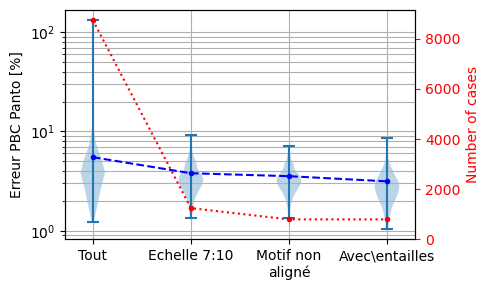

WORSE
honey_7_3_4_2
7.08


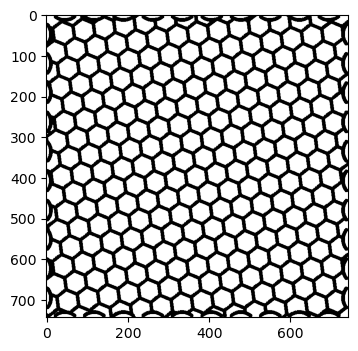

honey_7_9_0_4
7.05


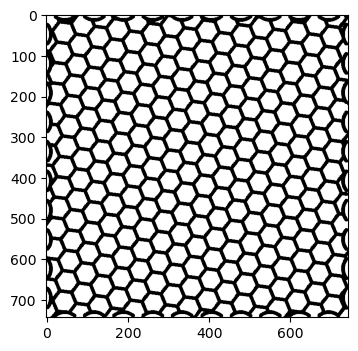

BEST
tria_7_3_0_0
1.35


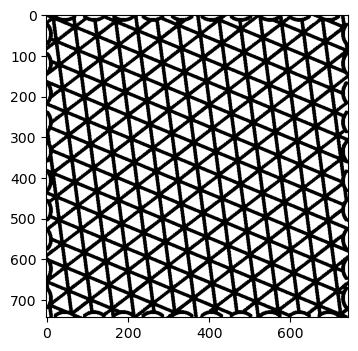

tria_7_9_0_0
1.35


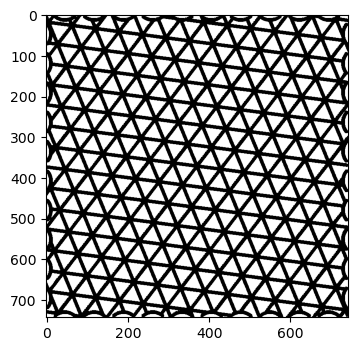

In [9]:

# ~ Elimination des cas problématiques

data_raw = get_bulk_data(read_data_from_campaigns(['campagne_honey','campagne_trian']))

data_list = [[], [], [], []]
last_tests_dict={}
eoi = (0, 3)
for test_id, test in data_raw.items():
    # * list of conditions
    stage = 0
    data_list[stage].append(test.global_err[eoi[0]][eoi[1]])

    if test.test_id.split('_')[1] not in ['7']:  # * Si l'angle est de 0 ou 15°
        continue
    stage += 1
    data_list[stage].append(test.global_err[eoi[0]][eoi[1]])

    
    if test.test_id.split('_')[0]=='carre':
        if test.test_id.split('_')[2] in ['0','1','15','16']:
            continue
    else:
        if test.test_id.split('_')[2] in ['0','1','6','11','12']:
            continue
    stage += 1
    data_list[stage].append(test.global_err[eoi[0]][eoi[1]])

    t_cc_name=test_id.split('_')
    t_cc_name[0]+='CC'
    t_cc=data_CC_bulk['_'.join(t_cc_name)]
    stage += 1
    data_list[stage].append(t_cc.global_err[eoi[0]][eoi[1]])

    last_tests_dict |= {test_id:test}


plt.figure(figsize=(5,3))
plt.yscale('log')
plt.violinplot(data_list, range(len(data_list)), widths=0.25,
               showmeans=False, showmedians=False, showextrema=True)


plt.plot(range(len(data_list)), [np.mean(np.array(i)) for i in data_list], 'b.--')

plt.xticks(range(len(data_list)), ['Tout', 'Echelle 7:10', 'Motif non\naligné', 'Avec\entailles'])
plt.ylim(bottom=0.0)
plt.ylabel('Erreur PBC Panto [%]')


plt.grid(True, which="both", ls="-")

plt.twinx()
plt.plot(range(len(data_list)), [len(i) for i in data_list], 'r.:')
plt.ylabel('Number of cases', color='r')
plt.tick_params(axis='y', colors='red')
plt.ylim(bottom=0.0)

plt.tight_layout()
plt.savefig('images/MS_full_selection.pdf')
plt.show()

print('WORSE')
wb_tests=get_worse_test(last_tests_dict,number=2)
for t in wb_tests:
    print(t.test_id)
    print(t.global_err[0][3])
    t.show_geo()

print('BEST')
wb_tests=get_best_test(last_tests_dict,number=2)
for t in wb_tests:
    print(t.test_id)
    print(t.global_err[0][3])
    t.show_geo()


Lecture des données réalisée en 0.70201s
WORSE
hexac_12_0_5_0
27.03


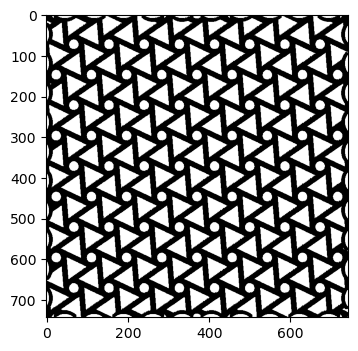

hexac_10_0_3_2
25.84


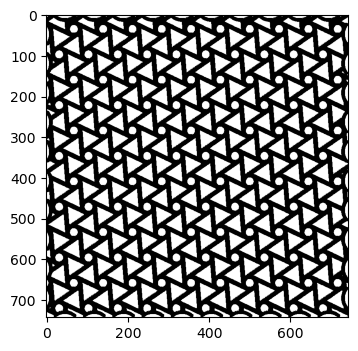

BEST
hexac_13_6_5_0
6.2


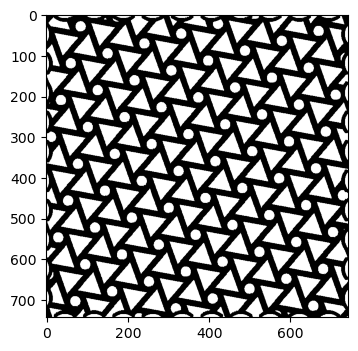

hexac_9_11_1_0
6.3


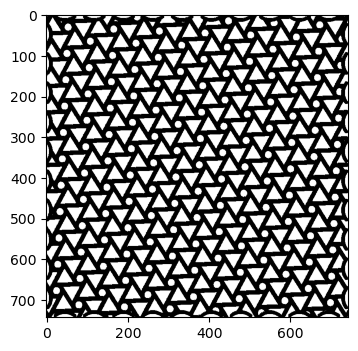

In [10]:
data_raw_hexac = get_bulk_data(read_data_from_campaigns(['campagne_hexac']))
                               
print('WORSE')
wb_tests=get_worse_test(data_raw_hexac,number=2)
for t in wb_tests:
    print(t.test_id)
    print(t.global_err[0][3])
    t.show_geo()

print('BEST')
wb_tests=get_best_test(data_raw_hexac,number=2)
for t in wb_tests:
    print(t.test_id)
    print(t.global_err[0][3])
    t.show_geo()